# EDA bổ sung — kiểm dữ liệu, mất cân bằng và tokenizer
    Notebook độc lập, dùng official snapshot như notebook 01. Chỉ mô tả dữ liệu;
    không thay split hoặc dùng test để chọn siêu tham số. Mọi biểu đồ được tính mới.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root
from src.datasets.goemotions import load_goemotions, multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES
ARTIFACTS = artifacts_root()
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.version.split()[0])
print('Dataset revision:', REVISION)
print('Artifacts:', ARTIFACTS.name)

import matplotlib.pyplot as plt
import seaborn as sns
frames, labels, manifest = load_goemotions(ARTIFACTS, write_metadata=False)
Y = {s: multi_hot(df.labels.tolist()) for s,df in frames.items()}
train = frames['train']
sns.set_theme(style='whitegrid', font='DejaVu Sans')

Python: 3.13.9
Dataset revision: add492243ff905527e67aeb8b80c082af02207c3
Artifacts: goemotions-multilabel-classification


## 1. Trùng văn bản giữa các split và xung đột nhãn

In [2]:
from itertools import combinations
overlaps=[]
for a,b in combinations(frames,2):
    left,right=frames[a],frames[b]
    assert not (set(left.id)&set(right.id))
    shared=set(left.text)&set(right.text)
    overlaps.append(dict(left=a,right=b,shared_texts=len(shared)))
display(pd.DataFrame(overlaps))
common=set(frames['train'].text)&set(frames['test'].text)
conflict=[]
for text in sorted(common):
    a={tuple(sorted(v)) for v in frames['train'].loc[frames['train'].text==text,'labels']}
    b={tuple(sorted(v)) for v in frames['test'].loc[frames['test'].text==text,'labels']}
    conflict.append(dict(text=text,train_label_sets=sorted(a),test_label_sets=sorted(b),different_label_sets=a!=b))
display(pd.DataFrame(conflict))
print('Giữ nguyên official split và báo hạn chế; không tự xóa hoặc chia lại.')

,left,right,shared_texts
0,train,validation,41
1,train,test,32
2,validation,test,10


,text,train_label_sets,test_label_sets,different_label_sets
0,And then everyone clapped,"[(27,)]","[(27,)]",False
1,Bless you.,"[(5,)]","[(5,)]",False
2,Go on...,"[(27,)]","[(27,)]",False
3,Good luck!,"[(5, 20), (15,), (20,)]","[(20,)]",True
4,Happy birthday!,"[(17,)]","[(15,)]",True
5,Happy cake day!,"[(13,), (13, 17), (15,), (17,)]","[(13,), (17,)]",True
6,How do you know this?,"[(7,)]","[(27,)]",True
7,How old are you?,"[(27,)]","[(7,)]",True
8,I agree with this,"[(4,)]","[(4,)]",False
9,I like it,"[(18,)]","[(18,)]",False


Giữ nguyên official split và báo hạn chế; không tự xóa hoặc chia lại.


## 2. Phân bố nhãn và nhóm valence dùng để mô tả

,label,train_count
16,grief,77
21,pride,111
23,relief,153
19,nervousness,164
12,embarrassment,303
24,remorse,545
14,fear,596
8,desire,641
11,disgust,793
13,excitement,853


,group,n_labels,assignments,assignment_share_pct
0,Positive,12,20023,39.181653
1,Negative,11,11132,21.783457
2,Ambiguous,4,5729,11.210692
3,Neutral,1,14219,27.824198


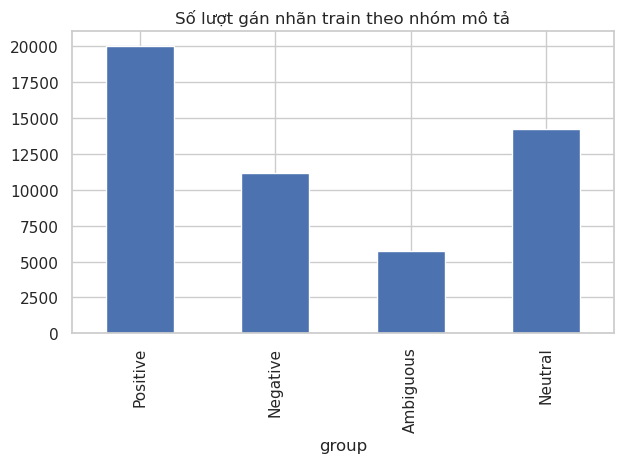

In [3]:
counts=Y['train'].sum(axis=0)
label_stats=pd.DataFrame({'label':labels,'train_count':counts})
display(label_stats.sort_values('train_count'))
taxonomy={
  'Positive':['admiration','amusement','approval','caring','desire','excitement','gratitude','joy','love','optimism','pride','relief'],
  'Negative':['anger','annoyance','disappointment','disapproval','disgust','embarrassment','fear','grief','nervousness','remorse','sadness'],
  'Ambiguous':['confusion','curiosity','realization','surprise'], 'Neutral':['neutral']}
assert sorted(sum(taxonomy.values(),[]))==sorted(labels)
groups=pd.DataFrame([dict(group=k,n_labels=len(v),assignments=int(label_stats.loc[label_stats.label.isin(v),'train_count'].sum())) for k,v in taxonomy.items()])
groups['assignment_share_pct']=groups.assignments/groups.assignments.sum()*100
display(groups)
groups.plot.bar(x='group',y='assignments',legend=False,title='Số lượt gán nhãn train theo nhóm mô tả')
plt.tight_layout();plt.show();plt.close()

## 3. Trọng số BCE tính chỉ từ train
    `pos_weight=(N-positive)/positive`; căn bậc hai là phương án mô tả thêm,
    chưa được thử như một cấu hình mới trong bộ số báo cáo.

In [4]:
weights=(len(train)-counts)/counts
weight_table=label_stats.assign(pos_weight=weights,sqrt_pos_weight=np.sqrt(weights))
display(weight_table.sort_values('train_count'))
assert np.isfinite(weights).all()

,label,train_count,pos_weight,sqrt_pos_weight
16,grief,77,562.766234,23.722694
21,pride,111,390.081081,19.750470
23,relief,153,282.725490,16.814443
19,nervousness,164,263.695122,16.238692
12,embarrassment,303,142.267327,11.927587
24,remorse,545,78.651376,8.868561
14,fear,596,71.835570,8.475587
8,desire,641,66.722309,8.168372
11,disgust,793,53.741488,7.330859
13,excitement,853,49.890973,7.063354


## 4. Ma trận đồng xuất hiện: tính bằng int64
    Multi-hot lưu bằng uint8 để tiết kiệm bộ nhớ. Phải ép int64 trước tích ma trận,
    nếu không các số đếm lớn hơn 255 có thể tràn. Đường chéo phải bằng support train.

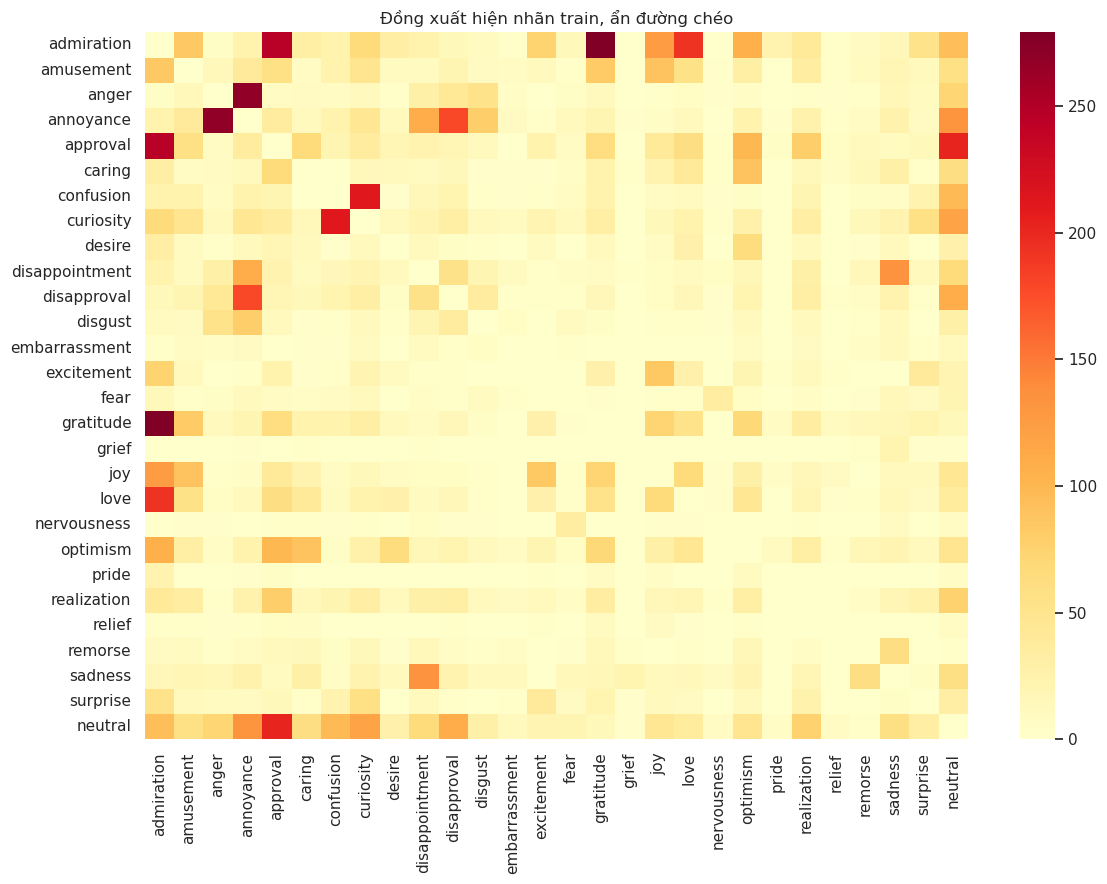

,label_a,label_b,count
14,admiration,gratitude,279
53,anger,annoyance,269
3,admiration,approval,246
147,confusion,curiosity,212
124,approval,neutral,202
17,admiration,love,192
84,annoyance,disapproval,178
222,disappointment,sadness,133
101,annoyance,neutral,132
16,admiration,joy,126


PASS: int64, ma trận đối xứng, đường chéo bằng support.


In [5]:
y64=Y['train'].astype(np.int64)
co=y64.T@y64
np.testing.assert_array_equal(np.diag(co),counts)
assert np.array_equal(co,co.T)
hidden=co.copy();np.fill_diagonal(hidden,0)
plt.figure(figsize=(12,9));sns.heatmap(pd.DataFrame(hidden,index=labels,columns=labels),cmap='YlOrRd')
plt.title('Đồng xuất hiện nhãn train, ẩn đường chéo');plt.tight_layout();plt.show();plt.close()
pairs=pd.DataFrame([dict(label_a=labels[a],label_b=labels[b],count=int(co[a,b])) for a,b in combinations(range(28),2)])
display(pairs.sort_values('count',ascending=False).head(15))
print('PASS: int64, ma trận đối xứng, đường chéo bằng support.')

## 5. Dấu câu, phủ định và placeholder Reddit

In [6]:
texts=train.text
masks={'[NAME]':texts.str.contains('[NAME]',regex=False),
    '[RELIGION]':texts.str.contains('[RELIGION]',regex=False),
    'exclamation':texts.str.contains('!',regex=False),
    'question':texts.str.contains('?',regex=False),
    'negation':texts.str.contains(r"\b(?:not|no|never|none|nothing|n't)\b",case=False,regex=True),
    'all_caps':texts.map(lambda t:t.isupper() and len(t.split())>2)}
lexical=pd.DataFrame([dict(feature=k,n_train=int(v.sum()),percent=float(v.mean()*100)) for k,v in masks.items()])
display(lexical)
print('Đếm dấu ? dạng literal; không tìm chuỗi backslash + dấu hỏi.')

,feature,n_train,percent
0,[NAME],6059,13.957613
1,[RELIGION],92,0.211933
2,exclamation,6022,13.872380
3,question,4581,10.552868
4,negation,6250,14.397604
5,all_caps,369,0.850035


Đếm dấu ? dạng literal; không tìm chuỗi backslash + dấu hỏi.


## 6. Độ dài token bằng tokenizer đã ghim revision
    Dùng đúng tokenizer BERT uncased đã ghi trong EDA lịch sử. Đây là phân tích
    tokenizer EDA, khác BERT cased của mô hình C1. Không dùng một revision main mới.

,percentile,word_count,BERT_uncased_tokens
0,50.0,12.0,19.0
1,75.0,18.0,26.0
2,90.0,22.0,31.0
3,95.0,24.0,34.0
4,99.0,27.0,38.0
5,99.5,28.0,39.0
6,100.0,33.0,316.0


Tokenizer revision: 86b5e0934494bd15c9632b12f734a8a67f723594 SHA-256: ce64fce797c24f68df90b40a3f74f579b336a493db14bd583fd520ea0d8c9a98
Tỷ lệ câu train dài hơn 128 token: 0.0023036166781847498 %


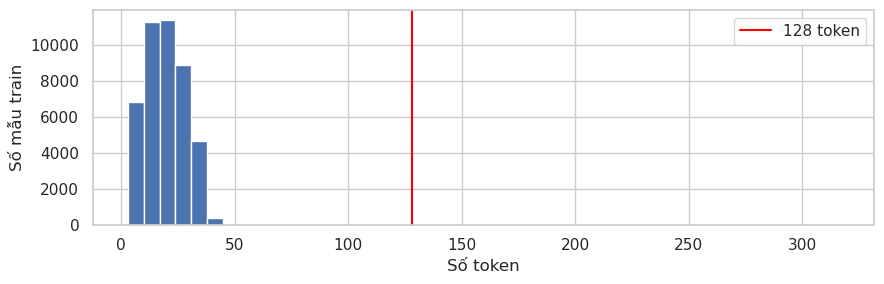

In [7]:
from tokenizers import Tokenizer
from src.datasets.goemotions import download
model_id='google-bert/bert-base-uncased'
revision=read_json(ROOT/'data/tokenizer_revisions.json')[model_id]
path=download(f'https://huggingface.co/{model_id}/resolve/{revision}/tokenizer.json',
              ROOT/f'data/tokenizers/BERT/{revision}/tokenizer.json')
tok=Tokenizer.from_file(str(path));tok.no_truncation();tok.no_padding()
lengths=np.array([len(e.ids) for e in tok.encode_batch(train.text.tolist())])
percentiles=[50,75,90,95,99,99.5,100]
display(pd.DataFrame({'percentile':percentiles,'word_count':np.percentile(train.text.str.split().str.len(),percentiles),
                      'BERT_uncased_tokens':np.percentile(lengths,percentiles)}))
print('Tokenizer revision:',revision,'SHA-256:',sha256(path))
print('Tỷ lệ câu train dài hơn 128 token:',float((lengths>128).mean()*100),'%')
plt.figure(figsize=(9,3));plt.hist(lengths,bins=45);plt.axvline(128,color='red',label='128 token')
plt.xlabel('Số token');plt.ylabel('Số mẫu train');plt.legend();plt.tight_layout();plt.show();plt.close()

## 7. Kiểm cuối: split, hỗ trợ nhãn và cardinality

In [8]:
rows=[]
for split,frame in frames.items():
    matrix=Y[split]
    assert matrix.shape==(len(frame),28)
    np.testing.assert_array_equal(matrix.sum(1),frame.labels.map(len))
    rows.append(dict(split=split,n_samples=len(frame),n_labels=28,
        multi_label_samples=int((matrix.sum(1)>1).sum()),cardinality=float(matrix.sum(1).mean())))
display(pd.DataFrame(rows))
print('PASS: mọi bảng/biểu đồ trong notebook được tính từ snapshot thật; không train model.')

,split,n_samples,n_labels,multi_label_samples,cardinality
0,train,43410,28,7102,1.177217
1,validation,5426,28,878,1.175820
2,test,5427,28,837,1.166206


PASS: mọi bảng/biểu đồ trong notebook được tính từ snapshot thật; không train model.
